# TP XGBoost

On va utiliser un vrai jeu de données assez volumineux : `nycflights13::flights` (environ 336 000 vols domestiques américains de 2013). Pour garder des temps d'exécution raisonnable, on n'utilisera que 50 000 vols.

**Objectif** : Prédire si un vol arrive avec un retard de plus de 15 minutes.

In [86]:
library(dplyr)
library(nycflights13)
library(xgboost)
library(pROC)
library(gbm)
library(knitr)

## Prétaitement des données

In [111]:
data(flights)

set.seed(123)
flights_clean <- flights |>
  filter(!is.na(arr_delay), !is.na(dep_delay), !is.na(air_time)) |>
  mutate(retard = ifelse(arr_delay > 15, 1, 0)) |>
  select(retard, dep_delay, air_time, distance, month, day, hour, minute) |>
  sample_n(50000)

n <- nrow(flights_clean)
prop <- round(mean(flights_clean$retard), 4)

cat("Proportion de vols en retard :", prop * 100, "%")

Proportion de vols en retard : 23.86 %

## Séparation des données en deux échantillons train et test

In [115]:
set.seed(123)
idx <- as.vector(caret::createDataPartition(factor(flights_clean$retard), p = 0.70, list = FALSE))

train_flights <- flights_clean[idx, ]
test_flights <- flights_clean[-idx, ]

cat("Proportion de vols en retard sur les données d'entrainement :", round(mean(train_flights$retard), 4) * 100, "%\n")
cat("Proportion de vols en retard sur les données de test :", round(mean(test_flights$retard), 4) * 100, "%")

X_train <- train_flights |> select(-retard) |> as.matrix()
y_train <- train_flights$retard
X_test <- test_flights |> select(-retard) |> as.matrix()
y_test <- test_flights$retard

Proportion de vols en retard sur les données d'entrainement : 23.86 %
Proportion de vols en retard sur les données de test : 23.85 %

## Premier modèle XGBoost (avec paramètres fixés)

In [116]:
boost_1 <- xgboost(data = X_train,
                   label = y_train,
                   objective = "binary:logistic",
                   eval_metric = "auc",
                   eta = 0.1,
                   nrounds = 100,
                   verbose = 0)

boost_1

##### xgb.Booster
raw: 381.1 Kb 
call:
  xgb.train(params = params, data = dtrain, nrounds = nrounds, 
    watchlist = watchlist, verbose = verbose, print_every_n = print_every_n, 
    early_stopping_rounds = early_stopping_rounds, maximize = maximize, 
    save_period = save_period, save_name = save_name, xgb_model = xgb_model, 
    callbacks = callbacks, objective = "binary:logistic", eval_metric = "auc", 
    eta = 0.1)
params (as set within xgb.train):
  objective = "binary:logistic", eval_metric = "auc", eta = "0.1", validate_parameters = "TRUE"
xgb.attributes:
  niter
callbacks:
  cb.evaluation.log()
# of features: 7 
niter: 100
nfeatures : 7 
evaluation_log:
  iter train_auc
 <num>     <num>
     1 0.9118637
     2 0.9124603
   ---       ---
    99 0.9637604
   100 0.9639847

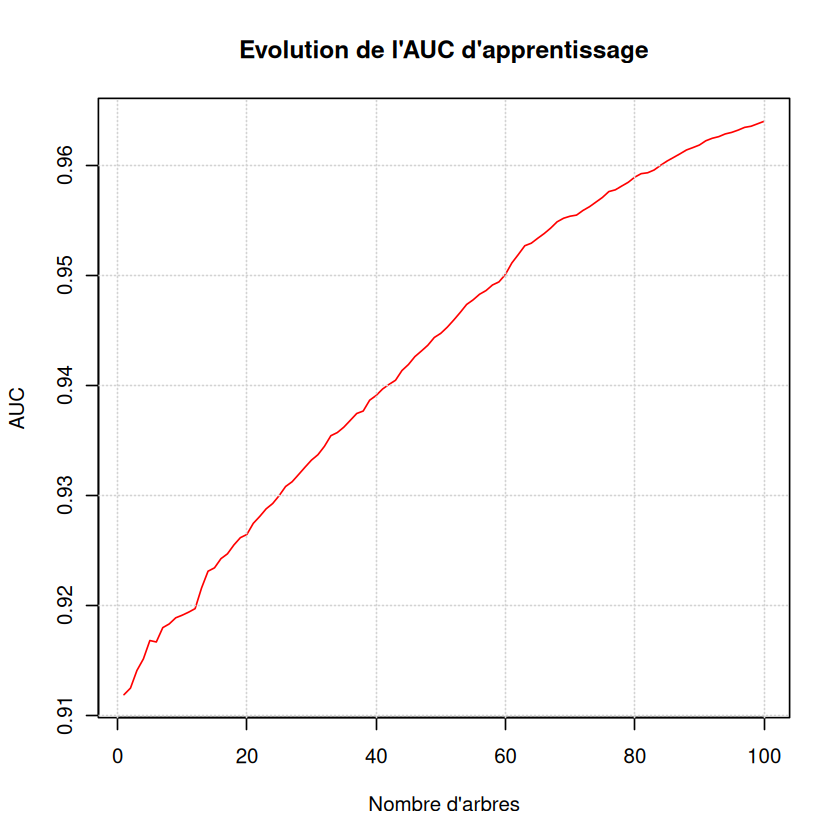

In [117]:
plot(boost_1$evaluation_log,
     xlab = "Nombre d'arbres",
     ylab = "AUC",
     main = "Evolution de l'AUC d'apprentissage",
     col = "red",
     type = "l")
grid(nx = NULL, ny = NULL, col = "lightgray")

Le `evaluation_log` montre l'AUC d'apprentissage passer d'environ 0.91 pour 1 arbre à environ 0.96 pour 100 arbres : le modèle apprend progressivement.

Cette AUC est mesurée sur l'apprentissage donc il peut y avoir du surapprentissage. On va donc faire une validation croisée pour choisir le bon nombre d'arbre.

## Sélection du nombre d'itération (nombre d'arbres) par validation croisée

In [ ]:
X_mat <- xgb.DMatrix(X_train, label = y_train)

sel_xgb <- xgb.cv(data = X_mat,
                  params = list(objective = "binary:logistic", eta = 0.1),
                  nrounds = 300,
                  metrics = "auc",
                  nfold = 10,
                  early_stopping_rounds = 10,
                  verbose = 0)

sel_xgb$evaluation_log |> head()
(ite_opt <- sel_xgb$best_iteration)
sel_xgb$niter

iter,train_auc_mean,train_auc_std,test_auc_mean,test_auc_std
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.9115632,0.0013752487,0.9073878,0.004449078
2,0.9133944,0.0010449580,0.9090295,0.005313647
3,0.9150727,0.0009533938,0.9108016,0.004827544
4,0.9159223,0.0009718332,0.9113128,0.005085369
5,0.9166977,0.0009364011,0.9118694,0.005252760
6,0.9175701,0.0009639995,0.9129114,0.004728078


[1] 232

[1] 242

## Modèle final et performance sur l'échantillon de test

AUC test : 0.947 
Accuracy test : 0.916 


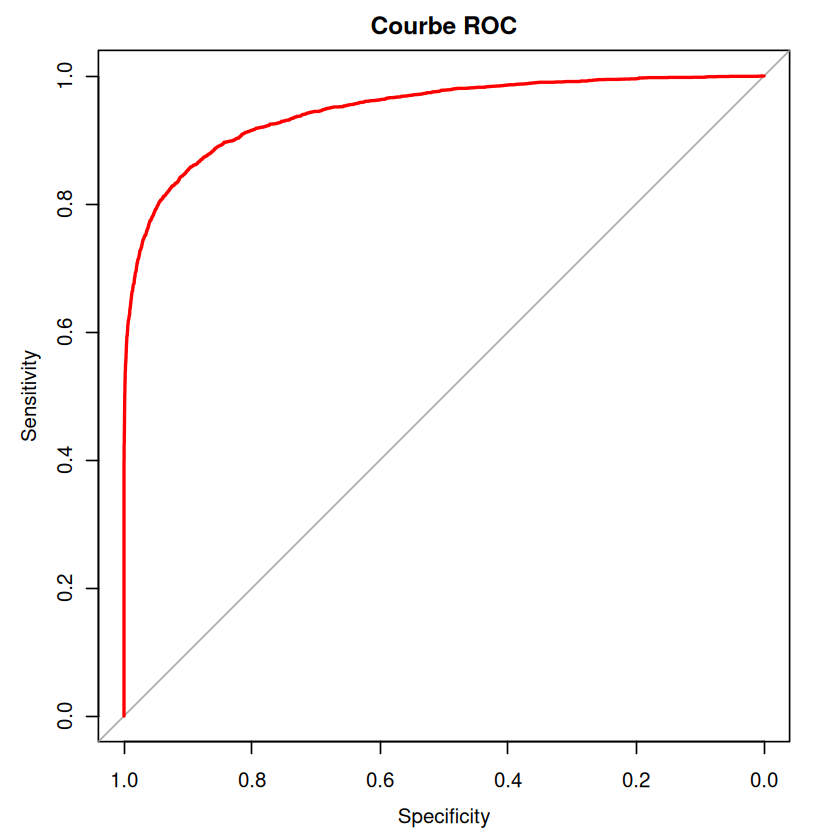

In [119]:
boost_opt <- xgboost(data = X_train,
                     label = y_train,
                     objective = "binary:logistic",
                     eta = 0.1,
                     nrounds = ite_opt,
                     verbose = 0)

prev_opt <- predict(boost_opt, newdata = X_test)

roc_flights <- roc(y_test, prev_opt, quiet = TRUE)
cat("AUC test :", round(auc(roc_flights), 3), "\n")
cat("Accuracy test :", round(mean((prev_opt > 0.5) == y_test), 3), "\n")

plot(roc_flights,
     main = "Courbe ROC",
     col = "red")

## Comparaison avec le Gradient boosting

On va comparer la vitesse puis les performances des deux modèles avec les mêmes paramètres.

In [121]:
n_trees <- 300
depth <- 3
learning_rate <- 0.1

time_gbm <- system.time({
  model_gbm <- gbm(
    retard ~ .,
    data = train_flights,
    distribution = "bernoulli",
    n.trees = n_trees,
    interaction.depth = depth,
    shrinkage = learning_rate,
    verbose = 0
  )
})

time_xgb <- system.time({
  model_xgb <- xgb.train(
    data = X_mat,
    objective = "binary:logistic",
    nrounds = n_trees,
    max_depth = depth,
    eta = learning_rate,
    verbose = 0
  )
})

time <- data.frame(
  modele = c("gbm", "xgboost"),
  temps_sec = c(time_gbm[["elapsed"]], time_xgb[["elapsed"]])
)
kable(time, digits = 3, caption = "Temps d'entraînement (secondes)")



Table: Temps d'entraînement (secondes)

|modele  | temps_sec|
|:-------|---------:|
|gbm     |     6.688|
|xgboost |     3.933|



Table: Performance sur le jeu de test

|modele  |   AUC| accuracy|
|:-------|-----:|--------:|
|gbm     | 0.937|    0.911|
|xgboost | 0.941|    0.913|

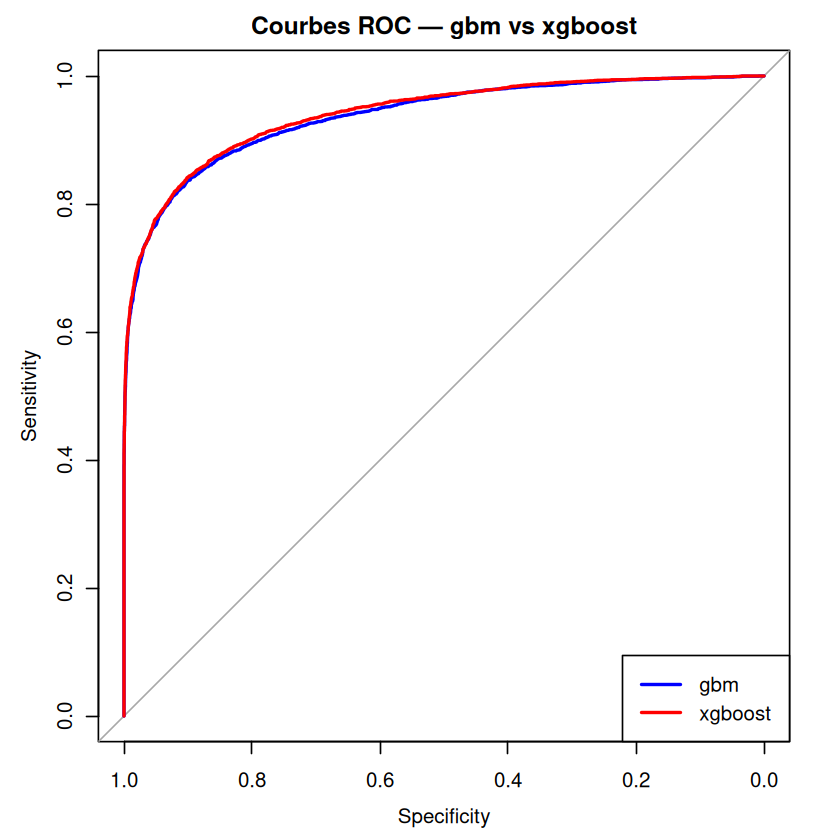

In [122]:
pred_gbm <- predict(model_gbm, newdata = test_flights, n.trees = n_trees, type = "response")
pred_xgb <- predict(model_xgb, newdata = X_test)

roc_gbm <- roc(y_test, pred_gbm, quiet = TRUE)
roc_xgb <- roc(y_test, pred_xgb, quiet = TRUE)

perf <- data.frame(
  modele   = c("gbm", "xgboost"),
  AUC      = c(auc(roc_gbm), auc(roc_xgb)),
  accuracy = c(
    mean((pred_gbm > 0.5) == y_test),
    mean((pred_xgb > 0.5) == y_test)
  )
)
kable(perf, digits = 3, caption = "Performance sur le jeu de test")

plot(roc_gbm, col = "blue", main = "Courbes ROC — gbm vs xgboost")
lines(roc_xgb, col = "red")
legend("bottomright", legend = c("gbm", "xgboost"), col = c("blue", "red"), lwd = 2)

## (BONUS) Exemple d'implémentation complète avec Tidymodels

Utilisation de la validation croisée pour sélectionner les meilleurs paramètres parmis une grille.
L'exécution de ce bout de code peut être très longue car on a 3 * 3 * 3 * 3 = 81 éléments dans notre grille et qu'on prend 10 groupes pour la validation croisée.

In [ ]:
library(tidymodels)

flights_clean <- flights_clean |>
  mutate(retard = factor(retard, levels = c(0, 1)))

set.seed(123)
split <- initial_split(flights_clean, prop = 0.70, strata = retard)
train_flights <- training(split)
test_flights  <- testing(split)

set.seed(123)
folds <- vfold_cv(train_flights, v = 10, strata = retard)

options(yardstick.event_first = FALSE) # pour considérer la deuxième classe ("1") comme évènement positif

xgb_spec <- boost_tree(
  trees = tune(),
  tree_depth = 3,
  learn_rate = 0.1,
  stop_iter = 10,
  loss_reduction = tune() # gamma
) |>
  set_engine(
    "xgboost",
    lambda = tune(), # régularisation L2
    alpha = tune() # régularisation L1
  ) |>
  set_mode("classification")

xgb_workflow <- workflow() |>
  add_formula(retard ~ .) |>
  add_model(xgb_spec)

grille <- tidyr::expand_grid(
  trees = c(100L, 200L, 300L),
  loss_reduction = c(0, 0.1, 1),
  lambda = c(0.1, 1, 10),
  alpha = c(0, 0.1, 1)
)

set.seed(123)
resultats_cv <- tune_grid(
  xgb_workflow,
  resamples = folds,
  grid = grille,
  metrics = metric_set(roc_auc)
)

show_best(resultats_cv, metric = "roc_auc")

meilleur <- select_best(resultats_cv, metric = "roc_auc")
meilleur

modele_final <- finalize_workflow(xgb_workflow, meilleur) |>
  fit(data = train_flights)

predictions <- bind_cols(
  test_flights |> select(retard),
  predict(modele_final, new_data = test_flights, type = "prob"),
  predict(modele_final, new_data = test_flights, type = "class")
)

roc_auc(
  predictions,
  truth = retard,
  .pred_1,
  event_level = "second"
)

accuracy(
  predictions,
  truth = retard,
  estimate = .pred_class
)